# City Temperature Anomalies and Warming Patterns
This project uses a predefined 27-city panel from Berkeley Earth's **GlobalLandTemperaturesByCity.csv**, distributed in Kaggle's Climate Change Earth Surface Temperature Data. All months from 1951 through 2012 are retained before cleaning. The input has eleven sourced attributes: seven city fields plus four global monthly temperature fields from GlobalTemperatures.csv in the same archive, joined many-to-one by month. Global context is repeated across cities and is not an independent local observation. Current global values are excluded from forecast predictors. Calendar, climatology and lag features are labeled as derived attributes.

[Dataset and license](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data) | [Berkeley Earth](https://berkeleyearth.org/data/). Provenance, selection and hashes: `data/provenance.json`. The data card lists CC BY-NC-SA 4.0; the bundled subset is a noncommercial educational adaptation with attribution.

The baseline is each city's calendar-month mean in 1951-1980. Supervised training uses 1981-2000, expanding validation ends in 1992, 1996 and 2000, and final testing uses 2001-2012. Regression predicts the anomaly for a month from information available before it. Classification predicts anomaly above +1 C, a project-defined event rather than a heatwave or global warming threshold. Earlier test-month observations can inform subsequent one-month forecasts; this is rolling evaluation, not a fixed-origin twelve-year forecast. The city panel is not an area-weighted global mean and ends in 2012.


In [15]:
from pathlib import Path  # Build portable file paths for the bundled data and generated outputs.
import json  # Save audit statistics and chosen parameters in a readable format.
import numpy as np  # Use numeric arrays, trigonometry and missing-value markers.
import pandas as pd  # Load and transform the monthly city data as tables.
import matplotlib.pyplot as plt  # Create, label and export figures.
import seaborn as sns  # Plot distributions and relationships using DataFrame columns.
from IPython.display import display  # Render tables directly below the notebook cell.
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, GridSearchCV
SEED=42  # Keep stochastic estimator results reproducible.
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)  # Create a local destination for tables, figures and audit files.
sns.set_theme(style='whitegrid')  # Apply a consistent plot style across deliverables.
def savefig(name):  # Use the same export and display settings for every figure.
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight'); plt.show(); plt.close()  # Fit labels, save the image, display it and release the figure.
raw=pd.read_csv('data/city_temperatures_1951_2012.csv')  # Read the eleven-column joined subset without changing its source file.
df=raw.drop_duplicates().copy()  # Remove exact repeated records while retaining the original DataFrame.
df['date']=pd.to_datetime(df.dt,errors='coerce')  # Parse dates; invalid text becomes NaT and is checked below.
for c in ['AverageTemperature','AverageTemperatureUncertainty']:
    df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan)  # Coerce nonnumeric or nonfinite temperature entries to missing values.
# Flag structurally implausible readings, not legitimate warm or cold extremes.
invalid=~df.AverageTemperature.between(-90,60) & df.AverageTemperature.notna()  # Flag temperatures outside broad physical bounds without deleting real extremes.
df.loc[invalid,'AverageTemperature']=np.nan  # Treat structurally invalid readings as missing outcomes.
assert not df.duplicated(['City','Country','date']).any()  # Require one record for each city-country-month key.
assert df.date.notna().all()  # Stop if any observation month could not be parsed.
df['city_id']=df.City+' | '+df.Country  # Disambiguate cities that share a name across countries.
def coordinate(s):
    return s.str[:-1].astype(float)*np.where(s.str[-1].isin(['S','W']),-1,1)  # Remove the hemisphere suffix and make south/west coordinates negative.
df['latitude']=coordinate(df.Latitude); df['longitude']=coordinate(df.Longitude)  # Convert both coordinate strings into signed numeric degrees.
df['year']=df.date.dt.year; df['month']=df.date.dt.month  # Extract calendar fields for the reference period and chronological splits.
# Climatology uses only 1951-1980: earlier than every supervised training fold.
reference=df[df.year.between(1951,1980)]  # Use only historical observations that precede all model training.
baseline=reference.groupby(['city_id','month']).AverageTemperature.agg(['mean','count']).rename(columns={'mean':'climatology','count':'baseline_count'})  # Estimate a separate normal temperature for each city and calendar month.
assert baseline.baseline_count.min()>=25  # Require adequate historical coverage for every monthly normal.
baseline.to_csv(OUT/'baseline_climatology.csv')  # Export the reference means and counts so anomalies can be audited.
df=df.join(baseline,on=['city_id','month'])  # Attach the matching historical monthly normal to every observation.
df['anomaly']=df.AverageTemperature-df.climatology  # Remove the local seasonal normal; positive values indicate warmer months.
# Ensure shift(1) means the previous calendar month: no compressed time gaps.
df=df.sort_values(['city_id','date']).reset_index(drop=True)  # Order each city chronologically before constructing past-only features.
assert df.groupby('city_id').date.diff().dropna().dt.days.between(28,31).all()  # Check that adjacent rows are consecutive calendar months within each city.
g=df.groupby('city_id')  # Keep lag calculations separate for every city.
df['lag1_anomaly']=g.anomaly.shift(1)  # Use the previous observed month, never the current target month.
df['lag12_anomaly']=g.anomaly.shift(12)  # Represent the same calendar month in the previous year.
df['prior12_mean']=g.anomaly.transform(lambda x:x.shift(1).rolling(12,min_periods=9).mean())  # Shift first, then average past anomalies to prevent target leakage.
df['lag1_uncertainty']=g.AverageTemperatureUncertainty.shift(1)  # Use only previously available measurement uncertainty.
df['month_sin']=np.sin(2*np.pi*df.month/12); df['month_cos']=np.cos(2*np.pi*df.month/12)  # Encode the circular annual cycle so December and January are neighbors.
df['time_years']=df.year-1981+(df.month-1)/12  # Represent long-term time progression with a fractional monthly component.
df['abs_latitude']=df.latitude.abs()  # Represent distance from the equator regardless of hemisphere.
df['hemisphere']=np.where(df.latitude>=0,'North','South')  # Create a descriptive grouping for geographic comparisons.
# Never impute a missing outcome. Predictors are imputed within each training fold.
model=df[df.year.between(1981,2012)&df.anomaly.notna()].sort_values(['date','city_id']).reset_index(drop=True)  # Keep supervised years with an observed target, then sort all cities by month.
model['warm_month']=(model.anomaly>1.0).astype(int)  # Define the positive class using the stated local +1 C anomaly threshold.
train=model[model.year<=2000].copy().reset_index(drop=True)  # Reserve 1981-2000 for estimator fitting and chronological model selection.
test=model[model.year>=2001].copy().reset_index(drop=True)  # Hold 2001-2012 apart for final performance evaluation.
assert train.date.max()<test.date.min()  # Ensure every training month precedes every final test month.
# Same month across all cities belongs to the same fold. No shuffled panel split.
cv=[]  # Store explicit row indices for expanding chronological validation windows.
for end,val_end in [(1988,1992),(1992,1996),(1996,2000)]:  # Expand training history and validate only on the following years.
    ti=np.flatnonzero(train.year.le(end)); vi=np.flatnonzero(train.year.between(end+1,val_end))  # Keep every city from a month on the same side of the fold boundary.
    assert train.iloc[ti].date.max()<train.iloc[vi].date.min()  # Verify that each validation fold contains only future observations.
    cv.append((ti,vi))  # Reuse identical temporal folds for regression and classification tuning.
num=['time_years','month_sin','month_cos','latitude','longitude','abs_latitude',
     'lag1_anomaly','lag12_anomaly','prior12_mean','lag1_uncertainty']
cat=['city_id']  # Treat city identity as categorical rather than assigning numeric ranks.
features=num+cat  # Select only the documented numeric and categorical predictors.
def preprocessing():  # Return a fresh transformer that each training fold fits independently.
    return ColumnTransformer([('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),num),  # Impute numeric gaps and standardize using training-fold statistics.
                             ('city',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])  # Encode city membership; unseen categories receive all-zero city indicators.
Xtr,Xte=train[features],test[features]  # Extract predictor tables without including current outcomes.
print('Raw rows:',len(raw),'Cities:',df.city_id.nunique(),'Engineered columns:',len(df.columns))
print('Train: 1981-2000',len(train),'Test: 2001-2012',len(test))
print('Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.')


Raw rows: 20088 Cities: 27 Engineered columns: 29
Train: 1981-2000 6480 Test: 2001-2012 3888
Evaluation is rolling one-month-ahead: prior test-month observations become available sequentially.


## Data preparation and exploration

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude,LandAverageTemperature,LandMaxTemperature,LandMinTemperature,LandAndOceanAverageTemperature
0,1951-01-01,24.755,0.459,Bangkok,Thailand,13.66N,99.91E,2.138,7.770,-3.521,13.341
1,1951-02-01,26.540,0.250,Bangkok,Thailand,13.66N,99.91E,2.332,8.163,-3.661,13.488
2,1951-03-01,29.049,0.400,Bangkok,Thailand,13.66N,99.91E,5.091,11.074,-1.087,14.278
3,1951-04-01,30.561,0.365,Bangkok,Thailand,13.66N,99.91E,8.367,14.538,2.191,15.198
4,1951-05-01,29.499,0.444,Bangkok,Thailand,13.66N,99.91E,11.438,17.371,5.376,16.158


<class 'pandas.DataFrame'>
RangeIndex: 20088 entries, 0 to 20087
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   dt                              20088 non-null  str    
 1   AverageTemperature              20088 non-null  float64
 2   AverageTemperatureUncertainty   20088 non-null  float64
 3   City                            20088 non-null  str    
 4   Country                         20088 non-null  str    
 5   Latitude                        20088 non-null  str    
 6   Longitude                       20088 non-null  str    
 7   LandAverageTemperature          20088 non-null  float64
 8   LandMaxTemperature              20088 non-null  float64
 9   LandMinTemperature              20088 non-null  float64
 10  LandAndOceanAverageTemperature  20088 non-null  float64
dtypes: float64(6), str(5)
memory usage: 1.7 MB
{'records': 20088, 'source_attributes': 11, 'engineered_attri

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
dt,20088,744,1951-01-01,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AverageTemperature,20088.0,NaN,NaN,NaN,16.26216,-18.943,10.88475,16.856,23.35925,36.339,8.876104
AverageTemperatureUncertainty,20088.0,NaN,NaN,NaN,0.334516,0.049,0.224,0.295,0.399,2.561,0.171655
City,20088,27,Bangkok,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,20088,22,United States,2232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,20088,24,52.24N,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Longitude,20088,27,99.91E,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandAverageTemperature,20088.0,NaN,NaN,NaN,8.953071,1.882,4.85525,9.272,13.1125,15.482,4.158363
LandMaxTemperature,20088.0,NaN,NaN,NaN,14.654949,7.229,10.42625,14.9915,18.918,21.32,4.258191
LandMinTemperature,20088.0,NaN,NaN,NaN,3.317405,-3.661,-0.74475,3.516,7.3135,9.715,4.058396


Joined source attributes: 11 Engineered attributes: 29


,rows,missing
city_id,,
Bangkok | Thailand,600,0
Berlin | Germany,600,0
Bombay | India,600,0
Cairo | Egypt,600,0
Cape Town | South Africa,600,0
Chicago | United States,600,0
Cordoba | Argentina,600,0
Jakarta | Indonesia,600,0
Lima | Peru,600,0


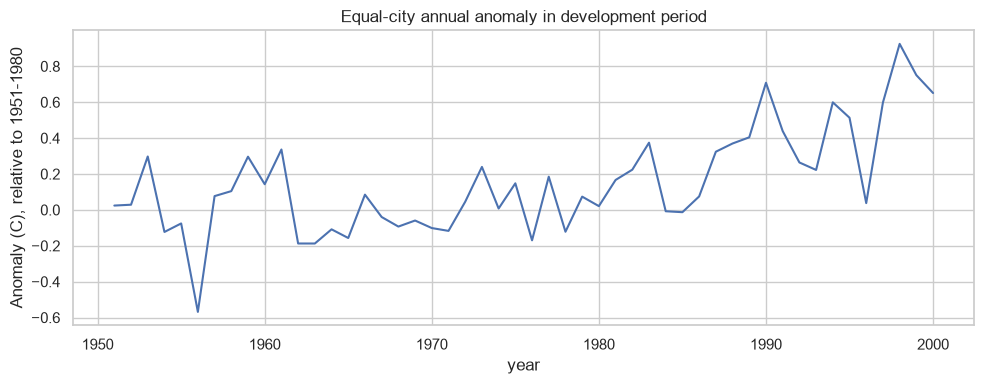

/opt/homebrew/lib/python3.11/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


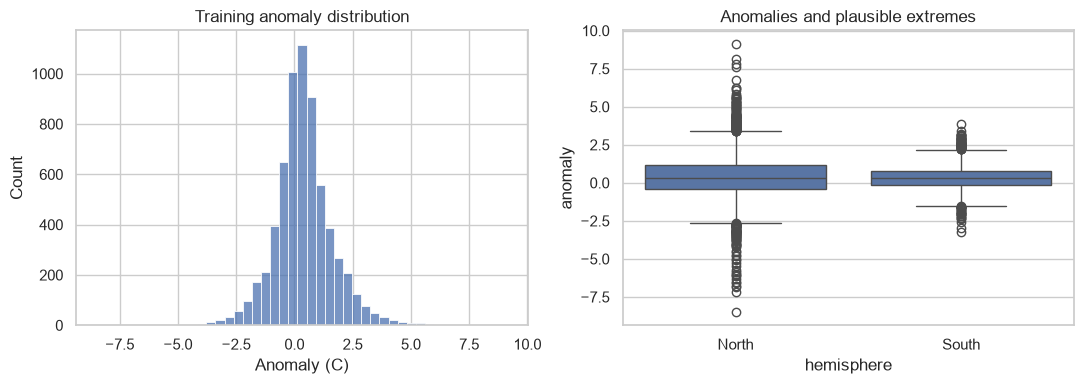

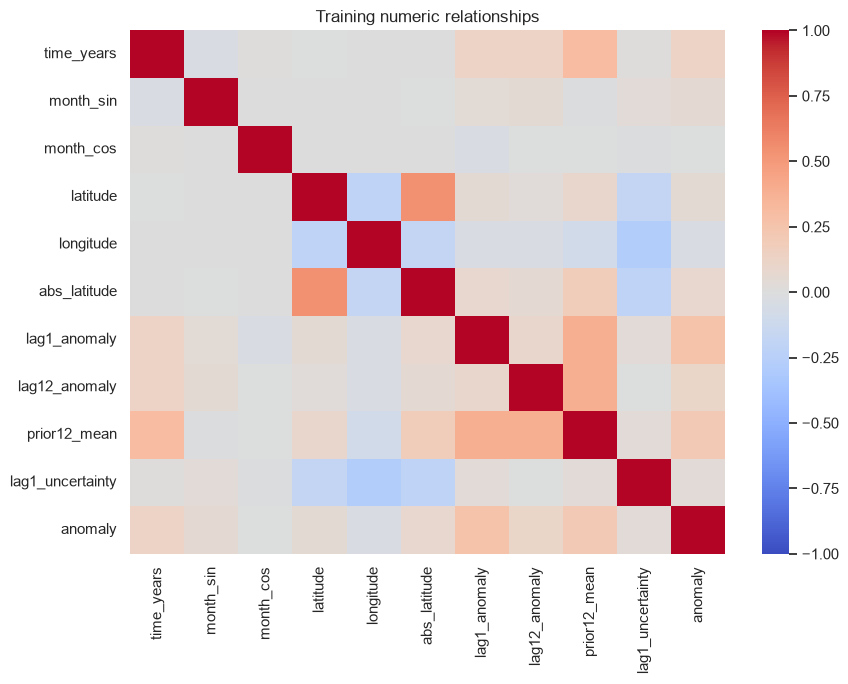

,date,LandAverageTemperature,LandMaxTemperature,LandMinTemperature,LandAndOceanAverageTemperature
count,600,600.000000,600.000000,600.000000,600.000000
mean,1975-12-16 10:57:36,8.812525,14.503962,3.188808,15.391010
min,1951-01-01 00:00:00,1.882000,7.229000,-3.661000,13.298000
25%,1963-06-23 12:00:00,4.665750,10.359000,-0.878250,14.213250
50%,1975-12-16 12:00:00,9.125500,14.830000,3.333500,15.439500
75%,1988-06-08 12:00:00,12.813750,18.634500,7.191250,16.582750
max,2000-12-01 00:00:00,15.340000,20.972000,9.715000,17.609000
std,NaN,4.154977,4.248587,4.065431,1.225962


Local IQR flags retained: 262


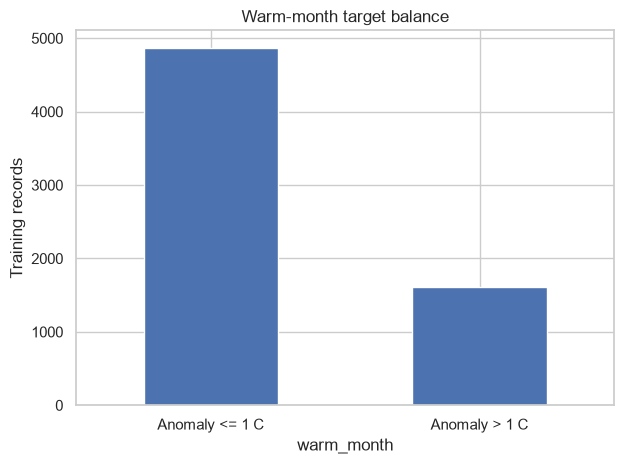

In [16]:
display(raw.head()); raw.info()  # Inspect example records, column types and missingness before analysis.
audit={'records':len(raw),'source_attributes':len(raw.columns),'engineered_attributes':len(df.columns),
       'cities':df.city_id.nunique(),'missing_temperature':int(raw.AverageTemperature.isna().sum()),
       'missing_uncertainty':int(raw.AverageTemperatureUncertainty.isna().sum()),
       'duplicates_removed':len(raw)-len(df),'invalid_temperatures':int(invalid.sum()),
       'missing_target_rows_excluded':int(df[df.year.between(1981,2012)].anomaly.isna().sum()),
       'train_records':len(train),'test_records':len(test)}
(OUT/'audit.json').write_text(json.dumps(audit,indent=2)); print(audit)  # Persist the cleaning and split audit alongside the notebook results.
display(df.describe(include='all').T)
# Save the complete engineered schema separately from the unmodified joined input.
df.to_csv(OUT/'analytical_dataset.csv',index=False)
print('Joined source attributes:',len(raw.columns),'Engineered attributes:',len(df.columns))  # Inspect summary statistics for the full analytical schema.
# Development EDA stops at 2000. Final-period trends are reported only in D4.
dev=df[df.year<=2000]  # Limit exploratory model-development plots to observations through 2000.
coverage=dev.groupby('city_id').agg(rows=('date','size'),missing=('AverageTemperature',lambda x:x.isna().sum()))  # Count available records and missing temperatures separately for each city.
coverage.to_csv(OUT/'coverage.csv');display(coverage)  # Save and display the city-level completeness check.
annual=dev.groupby(['year','city_id']).anomaly.mean().unstack()  # Arrange development-period annual anomalies into year-by-city columns.
annual.mean(axis=1).plot(figsize=(10,4));plt.ylabel('Anomaly (C), relative to 1951-1980');plt.title('Equal-city annual anomaly in development period');savefig('anomaly_trend')  # Plot an equally weighted city average rather than an area-weighted global mean.
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.histplot(train.anomaly,bins=45,ax=ax[0]);ax[0].set(xlabel='Anomaly (C)',title='Training anomaly distribution')  # Inspect the shape and spread of the training anomaly distribution.
sns.boxplot(data=train,x='hemisphere',y='anomaly',ax=ax[1]);ax[1].set_title('Anomalies and plausible extremes');savefig('distributions')  # Compare hemisphere distributions while retaining plausible extreme anomalies.
plt.figure(figsize=(9,7));sns.heatmap(train[num+['anomaly']].corr(),cmap='coolwarm',center=0,vmin=-1,vmax=1)  # Show training-only numeric correlations to identify redundant predictors.
plt.title('Training numeric relationships');savefig('correlations')
# Global context varies by month, not city; exclude current context from forecasts.
context_cols=['LandAverageTemperature','LandMaxTemperature','LandMinTemperature','LandAndOceanAverageTemperature']
display(dev[['date']+context_cols].drop_duplicates('date').describe())
assert not set(context_cols)&set(features)  # Prevent contemporaneous global information entering forecasts.
# City-month IQR flags respect local seasonality. Keep genuine weather extremes.
bounds=dev.groupby(['city_id','month']).AverageTemperature.quantile([.25,.75]).unstack()  # Calculate local seasonal quartiles instead of pooling unlike city climates.
bounds.columns=['q1','q3'];checked=dev.join(bounds,on=['city_id','month'])  # Attach the first and third quartiles to the corresponding city-month rows.
flag=(checked.AverageTemperature.lt(checked.q1-1.5*(checked.q3-checked.q1))|checked.AverageTemperature.gt(checked.q3+1.5*(checked.q3-checked.q1)))  # Flag values outside 1.5 IQR for inspection without automatically removing them.
print('Local IQR flags retained:',int(flag.sum()))
train.warm_month.value_counts().rename(index={0:'Anomaly <= 1 C',1:'Anomaly > 1 C'}).plot.bar(rot=0)  # Show class imbalance before judging classification accuracy.
plt.ylabel('Training records');plt.title('Warm-month target balance');savefig('class_balance')
# Export cleaned development data, never overwrite the source.
dev.to_csv(OUT/'cleaned_development.csv',index=False)  # Export cleaned development observations separately from the original subset.


## Decisions and implications
The eleven-column joined input exceeds the attribute minimum before feature engineering. Source temperature and uncertainty missingness are audited separately. Missing targets are excluded rather than fabricated; missing predictors are imputed within modeling folds. City-country-date keys must be unique, coordinates are converted with correct hemisphere signs, and consecutive calendar months are verified before lags. Temperatures outside -90 to 60 C are flagged as structural errors; ordinary extreme anomalies remain. Calendar-month climatology removes seasonality before warming comparisons. Correlations, uneven variability and class balance motivate regularization, chronological evaluation and F1/recall. Dataset selection is geographic convenience sampling and cannot support a global mean claim.

## Regression and evaluation

,cv_rmse_mean,cv_rmse_sd,test_mse,test_rmse,test_r2
model,,,,,
Mean baseline,1.337610,0.033022,1.794707,1.339667,-0.095533
Linear regression,1.264664,0.027444,1.539251,1.240666,0.060404
Ridge,1.263901,0.026916,1.538991,1.240561,0.060563
Climatology zero,NaN,NaN,2.241673,1.497222,-0.368372
Persistence,NaN,NaN,2.530361,1.590711,-0.544593


Selected using expanding-window CV: Ridge


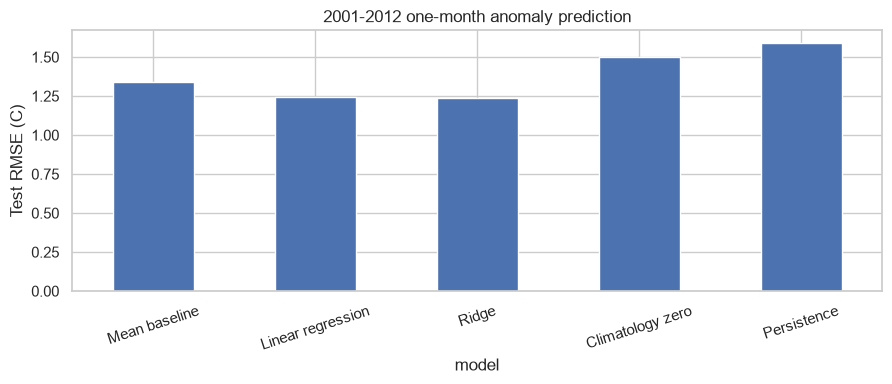

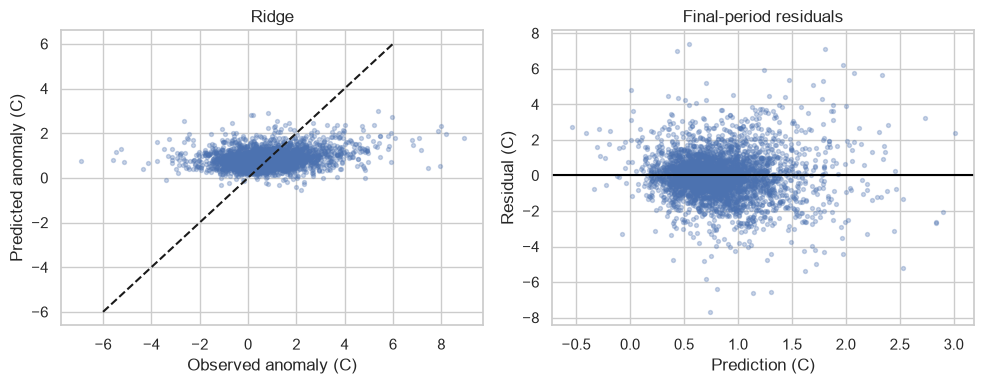

,feature_set,cv_rmse
0,Calendar and location,1.322365
1,Calendar location and past climate,1.263901


,records,mae,mse,rmse
city_id,,,,
Moscow | Russia,144,1.911341,6.656902,2.580097
Chicago | United States,144,1.472923,3.548478,1.883740
Berlin | Germany,144,1.447163,3.519698,1.876086
Toronto | Canada,144,1.421986,3.230546,1.797372
New York | United States,144,1.237344,2.476954,1.573834
Paris | France,144,1.227975,2.470322,1.571726
Los Angeles | United States,144,1.138798,2.104860,1.450814
Rome | Italy,144,1.093252,1.917593,1.384772
Madrid | Spain,144,1.120985,1.789444,1.337701


In [17]:
from sklearn.linear_model import LinearRegression,Ridge  # Import ordinary least squares and L2-regularized regression.
from sklearn.dummy import DummyRegressor  # Provide a fitted-mean reference for evaluating useful prediction.
from sklearn.metrics import mean_squared_error,r2_score
models={'Mean baseline':DummyRegressor(), 'Linear regression':LinearRegression(), 'Ridge':Ridge(alpha=10)}  # Compare the mean baseline with unregularized and regularized linear models.
rows=[];predictions={}  # Collect comparable metrics and retain predictions for residual diagnostics.
for name,est in models.items():  # Evaluate each regression estimator under the same temporal protocol.
    pipe=make_pipeline(preprocessing(),est)  # Fit preprocessing together with the estimator within each fold.
    scores=-cross_val_score(pipe,Xtr,train.anomaly,cv=cv,scoring='neg_root_mean_squared_error')  # Convert negative scorer values back into positive validation RMSE.
    pipe.fit(Xtr,train.anomaly);pred=pipe.predict(Xte);predictions[name]=pred  # Fit on development years and predict the reserved final period.
    rows.append(dict(model=name,cv_rmse_mean=scores.mean(),cv_rmse_sd=scores.std(),  # Summarize fold variability and held-out regression error.
                     test_mse=mean_squared_error(test.anomaly,pred),test_rmse=np.sqrt(mean_squared_error(test.anomaly,pred)),test_r2=r2_score(test.anomaly,pred)))
reg=pd.DataFrame(rows).set_index('model');winner=reg.cv_rmse_mean.idxmin()  # Choose the lowest training-CV RMSE without selecting on test performance.
# Explicit climate baselines: zero anomaly and previous-month anomaly.
for name,pred in [('Climatology zero',np.zeros(len(test))),('Persistence',test.lag1_anomaly.fillna(train.anomaly.mean()).to_numpy())]:  # Add zero-anomaly and previous-month persistence forecasts as climate baselines.
    reg.loc[name]=[np.nan,np.nan,mean_squared_error(test.anomaly,pred),np.sqrt(mean_squared_error(test.anomaly,pred)),r2_score(test.anomaly,pred)]  # Report test metrics; these reference forecasts have no fitted-model CV scores here.
display(reg);print('Selected using expanding-window CV:',winner);reg.to_csv(OUT/'regression_metrics.csv')
reg.test_rmse.plot.bar(figsize=(9,4),rot=18);plt.ylabel('Test RMSE (C)');plt.title('2001-2012 one-month anomaly prediction');savefig('regression_comparison')  # Compare all final-period regression errors in Celsius on one scale.
fig,ax=plt.subplots(1,2,figsize=(10,4));pred=predictions[winner]  # Inspect the predictions from the CV-selected regression model.
ax[0].scatter(test.anomaly,pred,s=8,alpha=.3);ax[0].plot([-6,6],[-6,6],'k--');ax[0].set(xlabel='Observed anomaly (C)',ylabel='Predicted anomaly (C)',title=winner)  # Compare predictions with observations; the dashed diagonal is perfect agreement.
ax[1].scatter(pred,test.anomaly.to_numpy()-pred,s=8,alpha=.3);ax[1].axhline(0,color='black');ax[1].set(xlabel='Prediction (C)',ylabel='Residual (C)',title='Final-period residuals');savefig('regression_residuals')  # Check residual structure around zero to reveal bias and missed extremes.
reg_predictions=test[['date','city_id','anomaly']].copy();reg_predictions['prediction']=pred;reg_predictions.to_csv(OUT/'regression_predictions.csv',index=False)  # Save predictions with their observation month and city for traceability.

# Check whether past-only anomaly features improve CV relative to calendar/location alone.
static_num=[c for c in num if c not in ['lag1_anomaly','lag12_anomaly','prior12_mean','lag1_uncertainty']]
static_prep=ColumnTransformer([('numeric',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),static_num),
                              ('city',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
static_scores=-cross_val_score(make_pipeline(static_prep,Ridge(alpha=10)),Xtr,train.anomaly,cv=cv,scoring='neg_root_mean_squared_error')
ablation=pd.DataFrame({'feature_set':['Calendar and location','Calendar location and past climate'],
                      'cv_rmse':[static_scores.mean(),reg.loc['Ridge','cv_rmse_mean']]})
display(ablation);ablation.to_csv(OUT/'feature_ablation.csv',index=False)  # Assess added features using training CV only.
# Inspect geographic error differences rather than relying solely on pooled metrics.
reg_predictions['absolute_error']=(reg_predictions.anomaly-reg_predictions.prediction).abs()
reg_predictions['squared_error']=(reg_predictions.anomaly-reg_predictions.prediction)**2
city_errors=reg_predictions.groupby('city_id').agg(records=('anomaly','size'),mae=('absolute_error','mean'),mse=('squared_error','mean'))
city_errors['rmse']=np.sqrt(city_errors.mse)
city_errors.to_csv(OUT/'city_errors.csv');display(city_errors.sort_values('rmse',ascending=False))  # Expose uneven local predictive reliability.


## Evaluation and feature rationale
Compare linear regression and ridge against a fitted mean baseline, zero anomaly climatology, and lag-one persistence. Table values include MSE, RMSE and R squared; CV scores come from three expanding chronological windows keeping every city's same month together. Choose by training CV RMSE, not held-out scores. City encoding captures persistent differences, cyclic features represent season, signed coordinates represent location, time represents trend, and past anomalies describe persistence. Current temperature, anomaly, uncertainty and warm label are excluded from predictors. Prior uncertainty is a quality proxy, not an extra climate driver. Low anomaly R squared is possible even when absolute seasonal temperatures would be easy to predict; assess improvement over meaningful baselines.

## Classification

{'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 50}


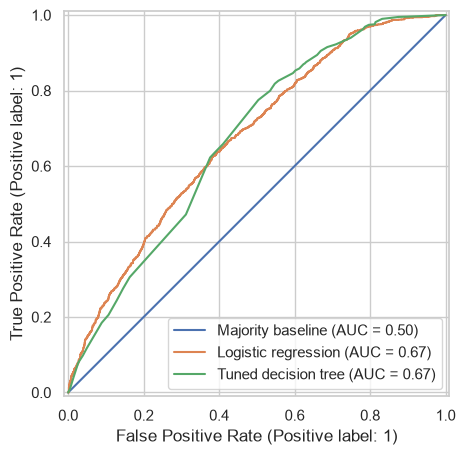

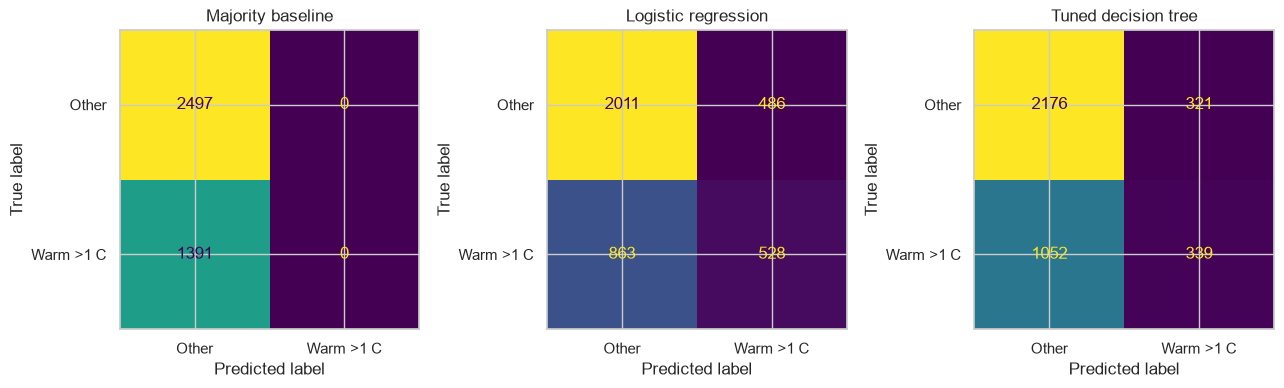

<Figure size 640x480 with 0 Axes>

,accuracy,f1,warm_recall,precision,auc
model,,,,,
Majority baseline,0.642233,0.000000,0.000000,0.000000,0.500000
Logistic regression,0.653035,0.439085,0.379583,0.520710,0.673262
Tuned decision tree,0.646862,0.330570,0.243710,0.513636,0.669384


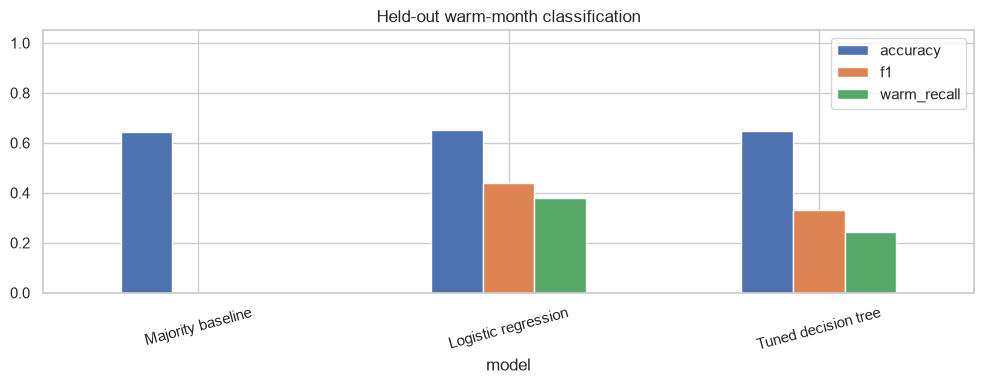

In [18]:
from sklearn.linear_model import LogisticRegression  # Model the probability of a positive warm-anomaly event.
from sklearn.tree import DecisionTreeClassifier  # Provide a nonlinear classifier with tunable complexity.
from sklearn.dummy import DummyClassifier  # Measure the accuracy achievable by always predicting the majority class.
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score,roc_auc_score,ConfusionMatrixDisplay,RocCurveDisplay
# Target = anomaly > 1 C. Current temperature/anomaly/uncertainty NEVER enter X.
assert not {'anomaly','warm_month','AverageTemperature','AverageTemperatureUncertainty','climatology'}&set(features)  # Prevent the current outcome or its direct components from entering predictors.
ytr,yte=train.warm_month,test.warm_month  # Extract the binary warm-event targets for the two time periods.
pipe=make_pipeline(preprocessing(),DecisionTreeClassifier(random_state=SEED))  # Keep tree preprocessing inside the chronological tuning pipeline.
search=GridSearchCV(pipe,{'decisiontreeclassifier__max_depth':[3,5,8],  # Search depth and minimum-leaf choices to control tree complexity.
                         'decisiontreeclassifier__min_samples_leaf':[20,50]},cv=cv,scoring='f1',n_jobs=1)  # Score six parameter combinations with positive-class F1 on temporal folds.
search.fit(Xtr,ytr);pd.DataFrame(search.cv_results_).to_csv(OUT/'tree_search.csv',index=False)  # Tune on training years only and retain the complete validation search results.
print(search.best_params_);(OUT/'tree_parameters.json').write_text(json.dumps(search.best_params_,indent=2))  # Record the chosen hyperparameters for reproducibility.
models={'Majority baseline':make_pipeline(preprocessing(),DummyClassifier(strategy='most_frequent')),  # Compare the majority reference, logistic model and CV-tuned tree.
        'Logistic regression':make_pipeline(preprocessing(),LogisticRegression(max_iter=1500,random_state=SEED)),
        'Tuned decision tree':search.best_estimator_}
rows=[];fig,axs=plt.subplots(1,3,figsize=(13,4));figroc,axroc=plt.subplots(figsize=(6,5))  # Prepare paired error-matrix and ROC comparisons for the same test observations.
for ax,(name,p) in zip(axs,models.items()):  # Evaluate every classifier on the identical reserved final-period rows.
    p.fit(Xtr,ytr);pred=p.predict(Xte);prob=p.predict_proba(Xte)[:,1]  # Generate class labels and positive-class probabilities from training-fitted models.
    rows.append(dict(model=name,accuracy=accuracy_score(yte,pred),f1=f1_score(yte,pred,zero_division=0),  # Measure overall accuracy and positive-class detection performance.
                     warm_recall=recall_score(yte,pred),precision=precision_score(yte,pred,zero_division=0),auc=roc_auc_score(yte,prob)))
    ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['Other','Warm >1 C'],ax=ax,colorbar=False);ax.set_title(name)  # Rows are actual labels and columns predictions; lower-left means a missed warm event.
    RocCurveDisplay.from_predictions(yte,prob,name=name,ax=axroc)  # Compare true-positive and false-positive rates over probability thresholds.
plt.figure(fig.number);savefig('confusion_matrices')
plt.figure(figroc.number);axroc.plot([0,1],[0,1],'k--');axroc.set_title('Warm anomaly ROC');savefig('roc')  # Add the random-ranking diagonal as an AUC reference.
cls=pd.DataFrame(rows).set_index('model');display(cls);cls.to_csv(OUT/'classification_metrics.csv')  # Display and export the final classification metric comparison.
cls[['accuracy','f1','warm_recall']].plot.bar(rot=15,figsize=(10,4));plt.ylim(0,1.05);plt.title('Held-out warm-month classification');savefig('classification_comparison')  # Contrast accuracy with F1 and warm-event recall under class imbalance.


## City clustering

,mean_temperature,temperature_sd,mean_anomaly,anomaly_sd,warm_fraction,latitude,seasonal_range,cluster
city_id,,,,,,,,
Bangkok | Thailand,27.624771,1.665215,0.108915,0.641884,0.083333,13.66,5.40515,1
Berlin | Germany,9.683325,6.961854,0.643336,2.073059,0.395833,52.24,18.29900,0
Bombay | India,27.131638,1.547574,0.224179,0.556924,0.070833,18.48,4.93330,1
Cairo | Egypt,21.563996,5.743424,-0.029338,1.017736,0.133333,29.74,15.56685,1
Cape Town | South Africa,16.620933,3.011305,0.440928,0.814793,0.254167,-32.95,8.30040,1
Chicago | United States,10.785196,8.224923,0.441868,2.007963,0.375000,42.59,23.24690,0
Cordoba | Argentina,17.472783,4.720212,0.411103,1.195572,0.283333,-31.35,13.35970,1
Jakarta | Indonesia,27.023367,0.548751,0.275036,0.385304,0.029167,-5.63,1.37580,1
Lima | Peru,17.267204,2.653025,0.407199,0.927468,0.208333,-12.05,6.88160,1


,mean_temperature,temperature_sd,mean_anomaly,anomaly_sd,warm_fraction,latitude,seasonal_range,cities
cluster,,,,,,,,
0,11.270174,7.754546,0.497609,1.604853,0.351282,43.213846,21.512550,13
1,21.105664,2.737053,0.273162,0.775979,0.155060,-4.823571,7.769179,14


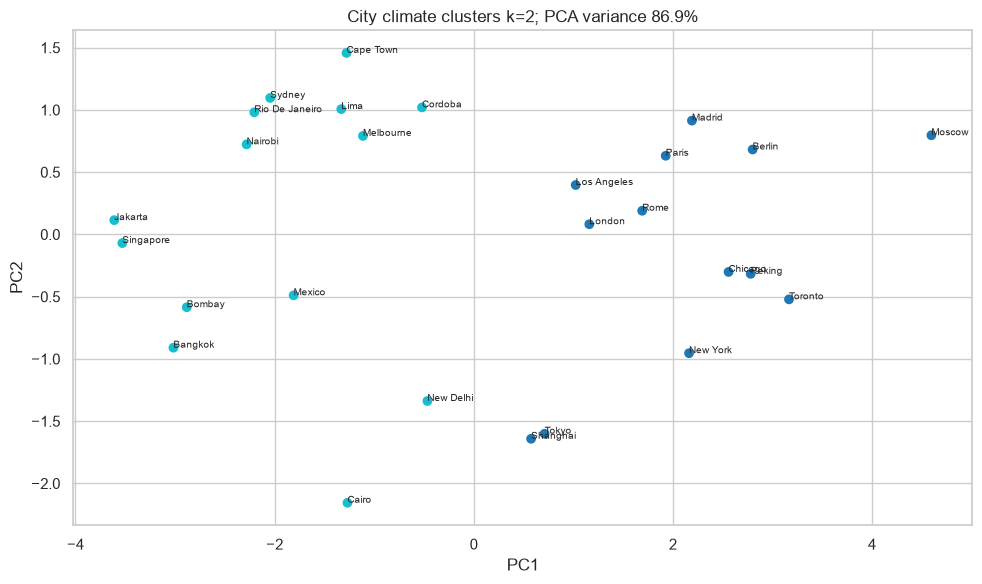

Clusters describe this city panel, not discrete global climate zones.


In [19]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
# Each city is one observation here; use ONLY 1981-2000 climate summaries.
profiles=train.groupby('city_id').agg(mean_temperature=('AverageTemperature','mean'),temperature_sd=('AverageTemperature','std'),  # Aggregate training records so one clustering observation represents one city.
     mean_anomaly=('anomaly','mean'),anomaly_sd=('anomaly','std'),warm_fraction=('warm_month','mean'),latitude=('latitude','first'))
seasonal=train.groupby(['city_id','month']).AverageTemperature.mean().unstack()  # Estimate each city's training-period monthly temperature cycle.
profiles['seasonal_range']=seasonal.max(axis=1)-seasonal.min(axis=1)  # Measure seasonality as the warmest minus coldest monthly mean.
z=StandardScaler().fit_transform(profiles)  # Give clustering summary features comparable scales before distance calculations.
scores=[];fitted={}  # Retain candidate silhouette values and fitted KMeans solutions.
for k in range(2,6):  # Explore two through five city groups using training summaries only.
    km=KMeans(n_clusters=k,n_init=30,random_state=SEED).fit(z)  # Use repeated centroid initializations and a reproducible random seed.
    scores.append({'k':k,'silhouette':silhouette_score(z,km.labels_)});fitted[k]=km  # Evaluate separation and cohesion while retaining the candidate model.
selection=pd.DataFrame(scores);kbest=int(selection.loc[selection.silhouette.idxmax(),'k']);km=fitted[kbest]  # Choose the candidate with the largest silhouette score.
selection.to_csv(OUT/'cluster_selection.csv',index=False)
profiles['cluster']=km.labels_;profiles.to_csv(OUT/'city_cluster_assignments.csv');display(profiles)  # Attach the chosen group to each city for interpretation.
summary=profiles.groupby('cluster').mean();summary['cities']=profiles.groupby('cluster').size();display(summary);summary.to_csv(OUT/'cluster_profiles.csv')  # Describe each cluster with average climate summaries and its city count.
proj=PCA(n_components=2,random_state=SEED);xy=proj.fit_transform(z)  # Project the standardized city summaries into two dimensions for display.
plt.figure(figsize=(10,6));plt.scatter(xy[:,0],xy[:,1],c=km.labels_,cmap='tab10')
for i,city in enumerate(profiles.index):plt.annotate(city.split(' | ')[0],xy[i],fontsize=7)  # Label individual cities so cluster assignments can be inspected.
plt.xlabel('PC1');plt.ylabel('PC2');plt.title(f'City climate clusters k={kbest}; PCA variance {proj.explained_variance_ratio_.sum():.1%}');savefig('clusters')
print('Clusters describe this city panel, not discrete global climate zones.')


## Association rules

,antecedents,consequents,support,confidence,lift
0,"north, prior_month_warm",warm_anomaly,0.088889,0.461538,1.849579
1,prior_month_warm,warm_anomaly,0.112037,0.451212,1.808196


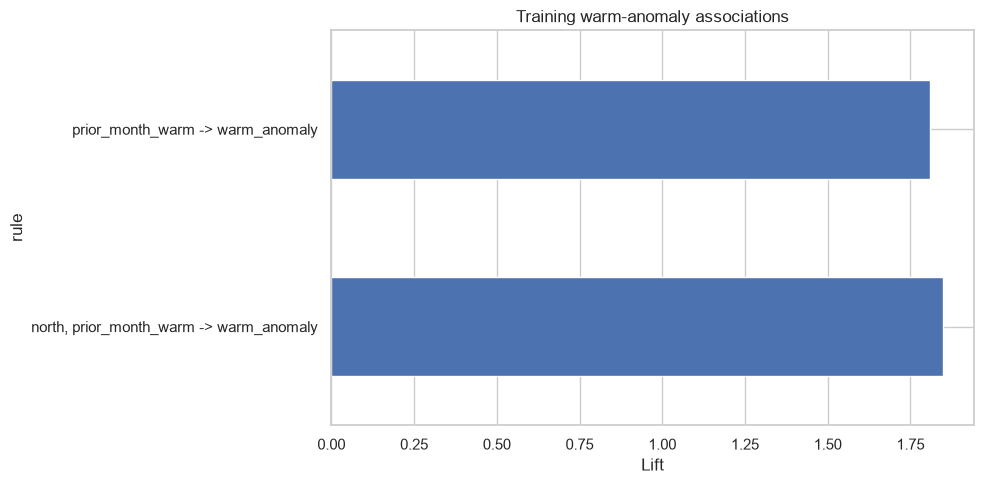

Descriptive rules: serial dependence and spatial correlation prevent an independent-sample causal interpretation.


In [20]:
from mlxtend.frequent_patterns import apriori,association_rules  # Mine frequent itemsets and conditional co-occurrence rules.
# Exploratory baskets use observed TRAINING anomalies, never future test outcomes.
# Warm events, prior warmth, latitude and later training era are distinct items.
basket=pd.DataFrame({'warm_anomaly':train.anomaly.gt(1),'prior_month_warm':train.lag1_anomaly.gt(1),  # Represent each training city-month as a basket of Boolean climate conditions.
                     'prior_year_warm':train.lag12_anomaly.gt(1),'north':train.latitude.ge(0),
                     'high_latitude':train.abs_latitude.ge(40),'later_training_era':train.year.ge(1991)})
frequent=apriori(basket,min_support=.08,use_colnames=True,max_len=3)  # Retain itemsets occurring in at least 8 percent of training rows, up to three items.
rules=association_rules(frequent,metric='confidence',min_threshold=.40)  # Generate exploratory rules meeting 40 percent conditional confidence.
# Exploratory sensitivity: .55 confidence yielded no qualifying warm rules.
# Report a .40 descriptive cutoff; this is not confirmatory hypothesis testing.
initial_count=int(((rules.consequents==frozenset(['warm_anomaly'])) & (rules.lift>1.1) & (rules.confidence>=.55)).sum())  # Record how many warm-event rules survive the stricter 55 percent confidence check.
(OUT/'rule_thresholds.json').write_text(json.dumps({'support':.08,'confidence':.40,'lift':1.1,'rules_at_confidence_055':initial_count},indent=2))  # Make the exploratory thresholds and sensitivity result explicit.
# Consequent is the warm anomaly of interest; exclude geographical tautologies.
rules=rules[(rules.consequents==frozenset(['warm_anomaly']))&(rules.lift>1.1)].copy()  # Keep warm-event consequents with lift above 1.1; drop geographical tautologies.
for c in ['antecedents','consequents']:rules[c]=rules[c].map(lambda x:', '.join(sorted(x)))  # Convert unordered item sets into readable, consistently sorted labels.
rules=rules.sort_values(['lift','confidence','antecedents'],ascending=[False,False,True]).reset_index(drop=True)  # Rank associations by lift and confidence with a reproducible text tie-break.
cols=['antecedents','consequents','support','confidence','lift'];rules=rules[cols]  # Keep the interpretable rule sides and support, confidence and lift metrics.
rules.to_csv(OUT/'association_rules.csv',index=False);display(rules)
if len(rules):
    top=rules.head(8).copy();top['rule']=top.antecedents+' -> warm_anomaly'  # Limit the plot to the strongest associations for readability.
    top.plot.barh(x='rule',y='lift',legend=False,figsize=(10,5));plt.xlabel('Lift');plt.title('Training warm-anomaly associations');savefig('rules')  # Visualize relative co-occurrence strength, without interpreting lift as causation.
else:
    plt.figure(figsize=(8,3));plt.text(.05,.5,'No rules passed the specified thresholds',fontsize=15);plt.axis('off');savefig('rules')
print('Descriptive rules: serial dependence and spatial correlation prevent an independent-sample causal interpretation.')


## Classification clustering and rule interpretation
Warm means anomaly strictly above +1 C relative to local 1951-1980 monthly climatology. Tune tree depth [3,5,8] and leaf size [20,50] across three chronological folds using positive-class F1. Compare logistic regression, tuned tree and majority baseline using accuracy, F1, precision, warm recall, ROC and AUC. Tuning scores are selection-biased; final test scores are independent of selection. KMeans groups 27 cities using development-period climate summaries, with k=2-5 chosen by silhouette. PCA and profile means describe the groups; climate states are continuous. Apriori rules use training data only, minimum support .08, confidence .40 and lift above 1.1, with warm_anomaly as consequent and at most three items. They identify descriptive co-occurrence; serial and spatial dependence invalidate simple independent-sample significance claims. Practical uses include research hypotheses and localized monitoring, not causal attribution.

## Final historical insights

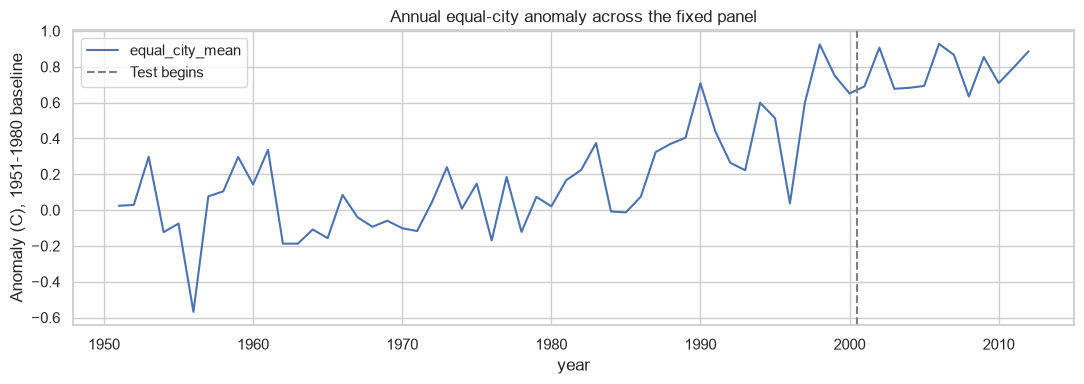

,reference_mean,recent_mean
city_id,,
Bangkok | Thailand,-1.184238e-16,0.388915
Berlin | Germany,-9.868649e-18,1.046546
Bombay | India,7.006741e-16,0.524750
Cairo | Egypt,-1.875043e-16,0.812812
Cape Town | South Africa,-1.825700e-16,0.576501
Chicago | United States,-5.921189e-17,0.986256
Cordoba | Argentina,-3.355341e-16,0.595618
Jakarta | Indonesia,-3.157968e-16,0.537072
Lima | Peru,3.947460e-17,0.370800


Equal-city 2001-2012 mean anomaly: 0.7768322530864197


In [21]:
# Descriptive final-period assessment follows model evaluation, not model tuning.
annual=df.groupby(['year','city_id']).anomaly.mean().unstack()  # Compute historical annual anomalies separately for each city.
# Annual means require all twelve monthly observations for each city-year.
counts=df.groupby(['year','city_id']).anomaly.count().unstack()  # Count observed months before accepting a city-year average.
annual=annual.where(counts.eq(12))  # Exclude incomplete city-years from the annual comparison.
annual['equal_city_mean']=annual.mean(axis=1)  # Give each available city equal weight; this is not a global area-weighted mean.
annual.to_csv(OUT/'annual_anomalies.csv')  # Export the historical annual series and equal-city summary.
annual.equal_city_mean.plot(figsize=(11,4));plt.axvline(2000.5,color='gray',linestyle='--',label='Test begins')  # Display the final historical curve and mark the start of the test period.
plt.ylabel('Anomaly (C), 1951-1980 baseline');plt.title('Annual equal-city anomaly across the fixed panel');plt.legend();savefig('final_anomaly_trend')
periods=df.groupby('city_id').apply(lambda x:pd.Series({'reference_mean':x.loc[x.year.between(1951,1980),'anomaly'].mean(),  # Compare each city's reference and final-period mean anomalies.
    'recent_mean':x.loc[x.year.between(2001,2012),'anomaly'].mean()}),include_groups=False)
periods.to_csv(OUT/'period_comparison.csv');display(periods)  # Preserve the city-specific warming comparison for report interpretation.
print('Equal-city 2001-2012 mean anomaly:',periods.recent_mean.mean())


## Ethics recommendations and limitations
This dataset contains city-level environmental estimates, with no personal identifiers. Geographic selection, sparse coverage and spatial correlation constrain fairness and generalization. Some communities and rural areas are not represented. Report city-specific errors and avoid allocating resources solely from this panel. Berkeley Earth's historical reconstruction already applies processing; our simple checks cannot redo its station homogenization. Source uncertainty is retained, but is not fully propagated into prediction intervals. Use the licensed data with attribution, distinguish evidence from interpretation, and communicate the 2012 endpoint. Validate on newer independent observations, expand geographic coverage, use proper gridded area weights for global claims, assess uncertainty and compare against stronger time-series baselines. Association and prediction cannot identify causes of climate change.

## Measured findings and reflection

### Preparation findings

The joined source has 11 attributes and 20,088 observations. Training warm-event prevalence is 25.0%; training anomaly standard deviation is 1.303 C. Local seasonality is removed by reference climatology, and class imbalance motivates warm-event F1 and recall alongside accuracy.

### Regression findings

Training CV selects Ridge: CV RMSE 1.264 C, test RMSE 1.241 C and test R squared 0.061. Ridge CV RMSE changes from 1.322 C with calendar/location to 1.264 C with past climate features. Geographic test RMSE ranges from 0.314 to 2.580 C, so pooled performance does not imply equal local reliability. The low anomaly R squared limits forecasting claims.

### Classification and pattern findings

Logistic regression test F1 is 0.439, warm recall 0.380, and AUC 0.673; the tuned tree F1 is 0.331. Most warm events remain missed at the default threshold, limiting alert use. KMeans selects 2 city groups. Group 0 has 13 cities, mean temperature 11.27 C and seasonal range 21.51 C. Group 1 has 14 cities, mean temperature 21.11 C and seasonal range 7.77 C. Apriori retains 2 exploratory warm-event rules. Their practical role is to guide independent monitoring hypotheses; overlapping rules are not independent evidence.